<a href="https://colab.research.google.com/github/at13lemmewrite/Data-Analytics-For-Manager---Super-Store/blob/main/assignment-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Case title: Improving sales profitability in a retail business

**Business question:** How can a retail business improve profitability while continuing to generate sales?

**Dataset:** Sample Superstore CSV (9,994 records and 21 columns).  
**Kaggle source:** https://www.kaggle.com/datasets/vivek468/superstore-dataset-final



## Case (150–200 words)

A retail business sells furniture, office supplies and technology products to customers across different regions of the United States. Each transaction record includes order and shipping dates, customer segment, product category, shipping mode, sales value, quantity, discount and profit. The business has to decide how to grow sales without allowing discounts, product costs or shipping choices to reduce profitability. The decision-makers are the retail management team, including the sales manager, category manager, regional sales managers and operations manager. They need to understand which products and regions contribute most to sales and profit, whether some product groups are consistently loss-making, and how discount levels are associated with profit. They also need to review delivery time across shipping modes and identify areas where operating decisions can be improved. This matters because high sales do not always mean high profit. If the business focuses only on revenue, it may continue selling products or offering discounts that reduce its overall returns. The analysis uses historical transaction data to identify patterns and recommend practical actions for pricing, product management, regional planning and shipping.

## Five business problems

1. **Discount and profitability:** Are higher discounts associated with lower transaction profit?
2. **Product performance:** Which categories and sub-categories generate the highest sales and profit, and which make losses?
3. **Regional performance:** Which regions contribute most to sales and profit, and where should management focus improvement?
4. **Customer segment performance:** Which customer segments contribute most to sales and profit?
5. **Shipping performance:** How do shipping modes differ in delivery time, sales and profit?



## Lecture 1–3: Foundations – import, load data, inspect and use Python basics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the CSV file in Google Colab
from google.colab import files
uploaded = files.upload()

# Read the dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print(df.head())
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.info()

Saving Sample - Superstore.csv to Sample - Superstore.csv
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Produc

### Variables, data structures and basic functions

### NumPy, Pandas Series and DataFrames


In [2]:
# NumPy array: a simple numerical example using values from the dataset
sales_array = np.array(df["Sales"].head(5))
print("First five sales values:", sales_array)
print("Array average:", round(np.mean(sales_array), 2))
print("Array total:", round(np.sum(sales_array), 2))

# Pandas Series: one column
sales_series = df["Sales"]
print("Series type:", type(sales_series))
print(sales_series.head())

# Pandas DataFrame: a selection of columns
sales_profit_df = df[["Order ID", "Category", "Sales", "Profit"]]
print("DataFrame type:", type(sales_profit_df))
display(sales_profit_df.head())

First five sales values: [261.96   731.94    14.62   957.5775  22.368 ]
Array average: 397.69
Array total: 1988.47
Series type: <class 'pandas.core.series.Series'>
0    261.9600
1    731.9400
2     14.6200
3    957.5775
4     22.3680
Name: Sales, dtype: float64
DataFrame type: <class 'pandas.core.frame.DataFrame'>


,Order ID,Category,Sales,Profit
0,CA-2016-152156,Furniture,261.9600,41.9136
1,CA-2016-152156,Furniture,731.9400,219.5820
2,CA-2016-138688,Office Supplies,14.6200,6.8714
3,US-2015-108966,Furniture,957.5775,-383.0310
4,US-2015-108966,Office Supplies,22.3680,2.5164



**Interpretation:** The displayed values are the first five sales records and a small view of the sales-and-profit table.


In [3]:
# LIST: product categories in this dataset
categories = ["Furniture", "Office Supplies", "Technology"]

# TUPLE: fixed information about the dataset
dataset_details = ("Sample Superstore", 2014, 2017)

# SET: unique regions
regions = set(df["Region"])

# DICTIONARY: business variable and its meaning
business_variables = {
    "Sales": "Revenue from a transaction line",
    "Profit": "Profit or loss from a transaction line",
    "Discount": "Discount applied to a transaction line",
    "Quantity": "Number of units"
}

print("List:", categories)
print("Tuple:", dataset_details)
print("Set:", regions)
print("Dictionary:", business_variables)
print(type(categories), type(dataset_details), type(regions), type(business_variables))

List: ['Furniture', 'Office Supplies', 'Technology']
Tuple: ('Sample Superstore', 2014, 2017)
Set: {'South', 'Central', 'West', 'East'}
Dictionary: {'Sales': 'Revenue from a transaction line', 'Profit': 'Profit or loss from a transaction line', 'Discount': 'Discount applied to a transaction line', 'Quantity': 'Number of units'}
<class 'list'> <class 'tuple'> <class 'set'> <class 'dict'>


In [4]:
# Accessing list, tuple, dictionary and set values
print("First category:", categories[0])
print("Last category:", categories[-1])
print("First two categories:", categories[0:2])

print("Dataset name:", dataset_details[0])
print("Meaning of Sales:", business_variables["Sales"])
print("Is West a region?", "West" in regions)

First category: Furniture
Last category: Technology
First two categories: ['Furniture', 'Office Supplies']
Dataset name: Sample Superstore
Meaning of Sales: Revenue from a transaction line
Is West a region? True


In [5]:
# Built-in functions using the Sales list
sales_list = df["Sales"].tolist()

print("Number of records:", len(sales_list))
print("Total sales:", round(sum(sales_list), 2))
print("Average sales per record:", round(sum(sales_list) / len(sales_list), 2))
print("Highest sales record:", max(sales_list))
print("Lowest sales record:", min(sales_list))
print("Top 5 sales records:", sorted(sales_list, reverse=True)[:5])

Number of records: 9994
Total sales: 2297200.86
Average sales per record: 229.86
Highest sales record: 22638.48
Lowest sales record: 0.444
Top 5 sales records: [22638.48, 17499.95, 13999.96, 11199.968, 10499.97]


In [6]:
# Decision making: if and else
average_profit = df["Profit"].mean()
print("Average profit per record:", round(average_profit, 2))

if average_profit >= 0:
    print("Average transaction profit is positive")
else:
    print("Average transaction profit is negative")

Average profit per record: 28.66
Average transaction profit is positive



**Interpretation:** A positive average means that the average transaction line generated profit. It does not mean every transaction was profitable.


In [7]:
# If, elif and else: classify the average transaction profit
if average_profit >= 50:
    print("High average profit")
elif average_profit >= 0:
    print("Positive but moderate average profit")
else:
    print("Average loss")

Positive but moderate average profit



**Interpretation:** A positive average means that the average transaction line generated profit. It does not mean every transaction was profitable.


In [8]:
# For loop with range() and iloc
for i in range(5):
    print(df["Product Name"].iloc[i], df["Sales"].iloc[i], df["Profit"].iloc[i])

Bush Somerset Collection Bookcase 261.96 41.9136
Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back 731.94 219.582
Self-Adhesive Address Labels for Typewriters by Universal 14.62 6.8714
Bretford CR4500 Series Slim Rectangular Table 957.5775 -383.031
Eldon Fold 'N Roll Cart System 22.368 2.5164


In [9]:
# While loop
i = 0

while i < 5:
    sales = df["Sales"].iloc[i]

    if sales >= 500:
        print("High sales:", sales)
    else:
        print("Sales below 500:", sales)

    i = i + 1

Sales below 500: 261.96
High sales: 731.94
Sales below 500: 14.62
High sales: 957.5775
Sales below 500: 22.368



**Interpretation:** This demonstrates how a condition can control repeated actions.


## Lecture 4–7: EDA and data quality

### First look at the dataset and classify variables

In [10]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nIndex:")
print(df.index)

print("\nData types:")
print(df.dtypes)

df.info()

Shape: (9994, 21)

Columns:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

Index:
RangeIndex(start=0, stop=9994, step=1)

Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries,

**Plain-English explanation:** This code performs the calculation or creates the output shown above. Read the variable names and comments to identify the data being selected, transformed or displayed.

**Interpretation:** Use the printed output or chart immediately above this explanation as the evidence for your written analysis.

**Limit / recommendation:** Do not make a business conclusion from the code alone. State what the actual output shows, mention any relevant limitation, and avoid claiming that an association proves cause and effect.

In [ ]:
number_cols = ["Sales", "Quantity", "Discount", "Profit"]
category_cols = [
    "Ship Mode", "Segment", "Country", "City", "State",
    "Region", "Category", "Sub-Category", "Product Name"
]
date_cols = ["Order Date", "Ship Date"]
id_cols = ["Row ID", "Order ID", "Customer ID", "Product ID"]

print("Numerical:", len(number_cols), number_cols)
print("Categorical:", len(category_cols), category_cols)
print("Date:", date_cols)
print("ID:", id_cols)

**My point :** The columns are grouped by their role in the analysis: numerical values, categories, dates and identifiers. This helps us choose suitable calculations and charts.

**Interpretation:** Sales, Profit, Quantity and Discount are numerical measures. Region, Segment and Category are groups. Order Date and Ship Date are dates. IDs identify records or entities.

**Limit:** Postal Code is a number in the file, but it is better treated as a location identifier rather than a quantity for averages or correlation.

### Data quality check

### Check inconsistent category entries and repeated identifiers

In [11]:
# Check text fields for leading/trailing spaces and inconsistent letter case
text_cols = ["Ship Mode", "Segment", "Country", "City", "State", "Region", "Category", "Sub-Category"]
for col in text_cols:
    values = df[col].dropna().astype(str)
    labels = pd.Series(values.unique())
    has_outer_spaces = values.ne(values.str.strip()).sum()
    normalised = labels.str.strip().str.casefold()
    variants = pd.DataFrame({"label": labels, "normalised": normalised})
    case_variants = variants.groupby("normalised")["label"].nunique()
    case_variants = case_variants[case_variants > 1].index.tolist()
    print(f"{col}: values with outer spaces = {has_outer_spaces}; case variants = {case_variants}")

# Display the most frequent labels for important categorical fields
for col in ["Region", "Category", "Ship Mode", "Segment"]:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

# Check exact duplicate rows separately from repeated order IDs
print("\nExact duplicate rows:", df.duplicated().sum())
print("Unique Order IDs:", df["Order ID"].nunique())
print("Rows per Order ID (top 10):")
print(df["Order ID"].value_counts().head(10))

Ship Mode: values with outer spaces = 0; case variants = []
Segment: values with outer spaces = 0; case variants = []
Country: values with outer spaces = 0; case variants = []
City: values with outer spaces = 0; case variants = []
State: values with outer spaces = 0; case variants = []
Region: values with outer spaces = 0; case variants = []
Category: values with outer spaces = 0; case variants = []
Sub-Category: values with outer spaces = 0; case variants = []

 Region
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

 Category
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

 Ship Mode
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

 Segment
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Exact duplicate rows: 0
Unique Order IDs: 5009
Rows per Order ID 

**my point:** This check looks for extra spaces and possible category-label inconsistencies. It also separates exact duplicate rows from repeated order numbers.

**Interpretation:** More than one row can belong to the same Order ID because an order may contain multiple product lines. Repeated Order IDs are not automatically duplicate records.

**Limit:** The case-variant check flags labels for inspection and  it does not prove that two labels are business errors.

**Recommendation:** Standardise category labels only after checking that the labels mean the same thing. Do not delete rows just because an Order ID appears more than once.

In [12]:
# Missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Total missing cells and percentage
total_blank = df.isnull().sum().sum()
print("Total blank cells:", total_blank)
print("Blank percentage:", round(total_blank / df.size * 100, 2), "%")

# Rows with at least one missing value
print("Rows with missing values:", df.isnull().any(axis=1).sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check unique identifiers
print("Are Row IDs unique?", df["Row ID"].is_unique)
print("Unique Order IDs:", df["Order ID"].nunique())

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Total blank cells: 0
Blank percentage: 0.0 %
Rows with missing values: 0
Duplicate rows: 0
Are Row IDs unique? True
Unique Order IDs: 5009


**my point:** This code checks how many blank values appear in each column, the overall percentage of blank cells, how many rows contain blanks, and whether any rows are exact duplicates. It also checks whether Row ID is unique and counts unique orders.

**Interpretation:** The supplied file has no missing cells and no exact duplicate rows. There are 5,009 unique Order IDs among 9,994 records. This confirms that an order may have several product lines.

**Limit / recommendation:** Do not remove repeated Order IDs as duplicates. They are expected because a single order can contain multiple products. Row ID is the record-level identifier.

### Missing-value heatmap

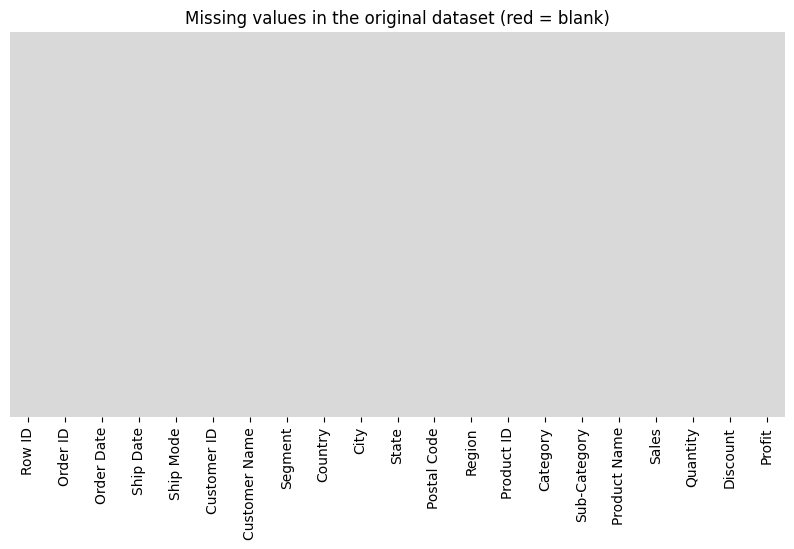

In [13]:
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#d9d9d9", "#fd2728"])

plt.figure(figsize=(10, 5))
sns.heatmap(
    df.isnull(),
    cmap=colors,
    cbar=False,
    yticklabels=False
)
plt.title("Missing values in the original dataset (red = blank)")
plt.show()

**my point:** This heatmap displays the missing-value pattern in the original dataset. Each row represents one record and each column represents a variable. The colours distinguish blank cells from available values.

**Interpretation:** Since the original dataset has no missing cells, the chart should show no red missing-value marks.


**my point for the Data-quality observation:** The supplied file has no missing cells and no exact duplicate rows. Therefore, we should not artificially delete rows or fill values that are not missing. The missing-value treatment methods below are demonstrated on a small temporary example, following the lecture method, so that the original Superstore data remains unchanged.

also, i believe that having this raw data go through cleaning would be beneficiary for me as i am following lecture pattern taught by you sir...please do consider. as my dataset does not have any missing value or duplicacy...for the matter of the subject and following lecture pattern, i have just pushed few missing value...and would do the cleaning for the same

In [14]:
# Small example to demonstrate missing-value treatment methods
sample_missing = df[["Sales", "Profit", "Region"]].head(10).copy()
sample_missing.iloc[1, 0] = np.nan
sample_missing.iloc[3, 1] = np.nan
sample_missing.iloc[5, 2] = np.nan

print(sample_missing)
print("\nMissing values:")
print(sample_missing.isnull().sum())

      Sales    Profit Region
0  261.9600   41.9136  South
1       NaN  219.5820  South
2   14.6200    6.8714   West
3  957.5775       NaN  South
4   22.3680    2.5164  South
5   48.8600   14.1694    NaN
6    7.2800    1.9656   West
7  907.1520   90.7152   West
8   18.5040    5.7825   West
9  114.9000   34.4700   West

Missing values:
Sales     1
Profit    1
Region    1
dtype: int64



**Interpretation:** The temporary example allows us to practise missing-value treatment methods even though the real Superstore file has no missing values.

**Limit:** These blanks are artificial and must never be reported as missing values in the actual Superstore dataset.

i would not be using it while making the executive report as my original data does not have this.


In [15]:
# Method 1: Drop rows containing missing values (temporary example)
sample_drop = sample_missing.dropna()

print("Rows before:", len(sample_missing))
print("Rows after:", len(sample_drop))
print("Data lost:", round((1 - len(sample_drop) / len(sample_missing)) * 100, 1), "%")
print("Blanks left:", sample_drop.isnull().sum().sum())

Rows before: 10
Rows after: 7
Data lost: 30.0 %
Blanks left: 0



**Interpretation:** The percentage shown tells us how much data would be lost if this method were used on that example.

**Limit / recommendation:** Dropping rows is appropriate only when the loss of information is acceptable. Do not apply it to the actual Superstore data because the actual file has no missing values.

In [16]:
# Method 2: Mean for numerical columns and mode for category
sample_mean = sample_missing.copy()

sample_mean["Sales"] = sample_mean["Sales"].fillna(sample_mean["Sales"].mean())
sample_mean["Profit"] = sample_mean["Profit"].fillna(sample_mean["Profit"].mean())
sample_mean["Region"] = sample_mean["Region"].fillna(sample_mean["Region"].mode()[0])

print(sample_mean)
print("Blanks left:", sample_mean.isnull().sum().sum())

        Sales    Profit Region
0  261.960000   41.9136  South
1  261.469056  219.5820  South
2   14.620000    6.8714   West
3  957.577500   46.4429  South
4   22.368000    2.5164  South
5   48.860000   14.1694   West
6    7.280000    1.9656   West
7  907.152000   90.7152   West
8   18.504000    5.7825   West
9  114.900000   34.4700   West
Blanks left: 0


**my point:** Missing numerical values are replaced with the column mean, while a missing Region is replaced with the most common Region (the mode).

**Interpretation:** This fills the blanks in the temporary example without deleting rows.

**Limit:** The mean can be affected by unusually high or low values. It is not always the best replacement for skewed business data, as taught in the class. This is a demonstration, not a cleaning step needed for the real file.

In [17]:
# Method 3: Median for numerical columns and mode for category
sample_median = sample_missing.copy()

sample_median["Sales"] = sample_median["Sales"].fillna(sample_median["Sales"].median())
sample_median["Profit"] = sample_median["Profit"].fillna(sample_median["Profit"].median())
sample_median["Region"] = sample_median["Region"].fillna(sample_median["Region"].mode()[0])

print(sample_median)
print("Blanks left:", sample_median.isnull().sum().sum())

      Sales    Profit Region
0  261.9600   41.9136  South
1   48.8600  219.5820  South
2   14.6200    6.8714   West
3  957.5775   14.1694  South
4   22.3680    2.5164  South
5   48.8600   14.1694   West
6    7.2800    1.9656   West
7  907.1520   90.7152   West
8   18.5040    5.7825   West
9  114.9000   34.4700   West
Blanks left: 0


**my point** This method replaces missing numerical values with the median and replaces the missing category with its most common value.

**Interpretation:** The median is the middle value after sorting the observations. It is generally less affected by extreme values than the mean.



In [18]:
# Method 4: Mode (most common value)
sample_mode = sample_missing.copy()

for col in sample_mode.columns:
    sample_mode[col] = sample_mode[col].fillna(sample_mode[col].mode()[0])

print(sample_mode)
print("Blanks left:", sample_mode.isnull().sum().sum())

      Sales    Profit Region
0  261.9600   41.9136  South
1    7.2800  219.5820  South
2   14.6200    6.8714   West
3  957.5775    1.9656  South
4   22.3680    2.5164  South
5   48.8600   14.1694   West
6    7.2800    1.9656   West
7  907.1520   90.7152   West
8   18.5040    5.7825   West
9  114.9000   34.4700   West
Blanks left: 0


**my point:** This code replaces missing values in each column with that column's most common value, known as the mode.

**Interpretation:** It is a simple method that can be used for categories and, where appropriate, numerical values.

**Limit:** For numerical columns, mode may not be representative when values are spread out. Select a missing-value method based on the meaning and distribution of each variable.

i have done this for the sake of the assignment and showcasing that i hold the knowlege to remove duplicacy and find missing value and how to treat it

### Descriptive statistics and unusual values

### Mean, median, mode, variance, standard deviation and quartiles

In [20]:

number_cols = ["Sales", "Quantity", "Discount", "Profit"]


In [21]:
# Calculate the descriptive measures requested in the assignment
stat_rows = []
for col in number_cols:
    stat_rows.append({
        "Variable": col,
        "Mean": df[col].mean(),
        "Median": df[col].median(),
        "Mode": df[col].mode().iloc[0],
        "Variance": df[col].var(),
        "Standard Deviation": df[col].std(),
        "Q1 (25%)": df[col].quantile(0.25),
        "Q2 (50%)": df[col].quantile(0.50),
        "Q3 (75%)": df[col].quantile(0.75)
    })

descriptive_measures = pd.DataFrame(stat_rows).set_index("Variable")
display(descriptive_measures.round(3))

,Mean,Median,Mode,Variance,Standard Deviation,Q1 (25%),Q2 (50%),Q3 (75%)
Variable,,,,,,,,
Sales,229.858,54.490,12.96,388434.455,623.245,17.280,54.490,209.940
Quantity,3.790,3.000,3.00,4.951,2.225,2.000,3.000,5.000
Discount,0.156,0.200,0.00,0.043,0.206,0.000,0.200,0.200
Profit,28.657,8.666,0.00,54877.798,234.260,1.729,8.666,29.364


**my point:** The mean is the average, the median is the middle value, and the mode is the most common value. Variance and standard deviation describe how spread out the values are. Quartiles divide the observations into four parts.

**Interpretation:** Compare mean and median to understand whether unusually large or small values may be pulling the average. A larger standard deviation means the values are more spread out.


In [22]:
df[number_cols].describe().round(2)

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98




**Interpretation:** These statistics summarise the distribution of Sales, Quantity, Discount and Profit. The median and quartiles help us understand typical values, while the minimum and maximum show the range.

**Limit:** Sales and Profit may be skewed by unusually large transactions. Therefore, the mean should be read together with the median and boxplots.

In [23]:
# Compare mean and median
gap = pd.DataFrame({
    "Mean": df[number_cols].mean(),
    "Median": df[number_cols].median()
})

gap["Gap %"] = (
    (gap["Mean"] - gap["Median"]) /
    gap["Median"].replace(0, np.nan) * 100
)

gap.round(2)

,Mean,Median,Gap %
Sales,229.86,54.49,321.84
Quantity,3.79,3.00,26.32
Discount,0.16,0.20,-21.90
Profit,28.66,8.67,230.66


**my point for explanation:** This table compares the mean and median for each numerical variable and calculates the percentage difference between them.

**Interpretation:** A large gap between mean and median can indicate that a variable is skewed or contains extreme values.

**Limit:** The percentage gap is not meaningful when a median is zero or very close to zero. In those cases, use the mean and median values directly.

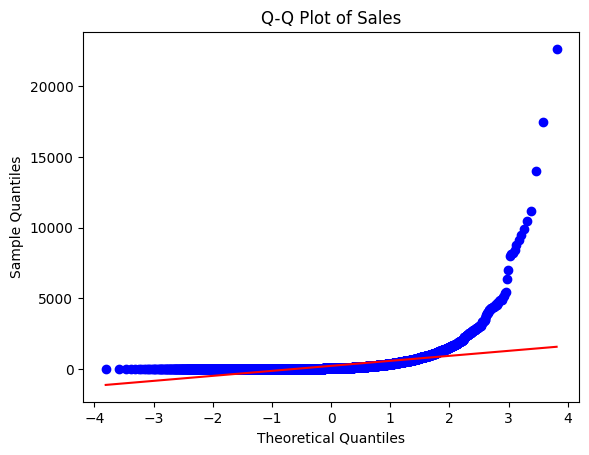

In [24]:
# Q-Q plot of Sales
import scipy.stats as stats

sales_values = df["Sales"].dropna()

stats.probplot(sales_values, dist="norm", plot=plt)
plt.title("Q-Q Plot of Sales")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

**explanation:** `dropna()` removes rows that contain at least one missing value from the temporary example. The code compares the number of rows before and after removal.

**Interpretation:** The percentage shown tells us how much data would be lost if this method were used on that example.

**Limit / recommendation:** Dropping rows is appropriate only when the loss of information is acceptable.i wouldnot be copying the actual Superstore data because the actual file has no missing values.

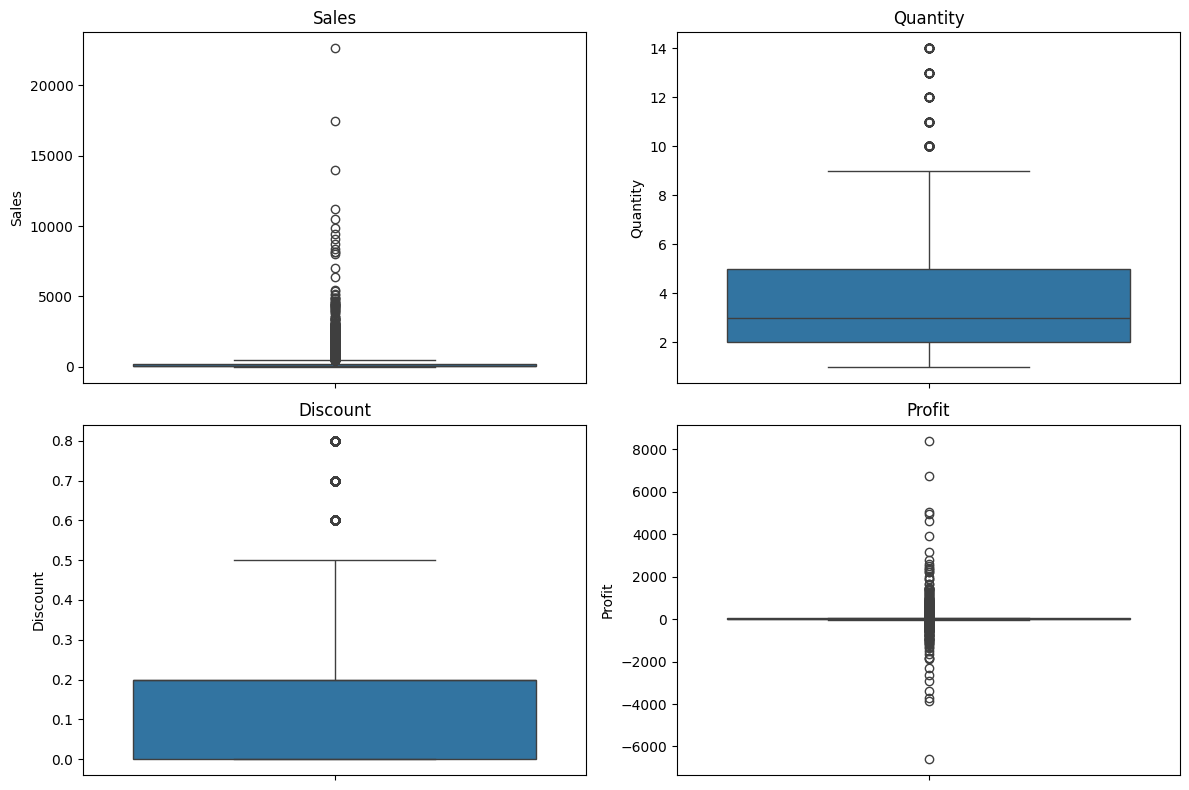

In [25]:
# Boxplot of each numerical variable
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(number_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

**my point:** These boxplots show the median, middle 50% of observations and potential extreme values for each numerical variable.

**Interpretation:** Points beyond the whiskers or ranges are flagged as possible outliers. They should be checked rather than automatically removed.

**Limit / recommendation:** An unusual value may be a genuine high-value sale or a genuine loss.

**Outlier decision:** Sales and Profit contain large values and negative profit values. These may be genuine large orders or genuine losses, not data-entry errors. will identify and describe them, but will not cap or delete the original business values without evidence

In [26]:
# IQR limits for Sales (inspect unusual values; do not automatically remove)
col = "Sales"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower limit:", round(lower, 2))
print("Upper limit:", round(upper, 2))
print("Values below lower limit:", (df[col] < lower).sum())
print("Values above upper limit:", (df[col] > upper).sum())

Q1: 17.28
Q3: 209.94
IQR: 192.66
Lower limit: -271.71
Upper limit: 498.93
Values below lower limit: 0
Values above upper limit: 1167


In [27]:
# Demonstrate capping on a copy only
df_capped = df.copy()
df_capped[col] = df_capped[col].clip(lower, upper)

comparison = pd.DataFrame({
    "Before Capping": df[col].describe(),
    "After Capping": df_capped[col].describe()
})

display(comparison.round(2))
print("Maximum before:", round(df[col].max(), 2))
print("Maximum after:", round(df_capped[col].max(), 2))
print("Upper limit:", round(upper, 2))

,Before Capping,After Capping
count,9994.00,9994.00
mean,229.86,140.28
std,623.25,168.80
min,0.44,0.44
25%,17.28,17.28
50%,54.49,54.49
75%,209.94,209.94
max,22638.48,498.93


Maximum before: 22638.48
Maximum after: 498.93
Upper limit: 498.93


**my understanding for this:** This code creates a separate copy of the dataset and caps Sales values at the IQR limits. It compares descriptive statistics before and after capping.

**Interpretation:** Capping reduces the influence of very high values on some summary statistics.

**Limit / recommendation:** Capping changes the original values and can understate genuine sales. We retain the original dataset for the main business analysis and use this copy only to demonstrate the technique.

### Before-and-after capping chart (lecture method)


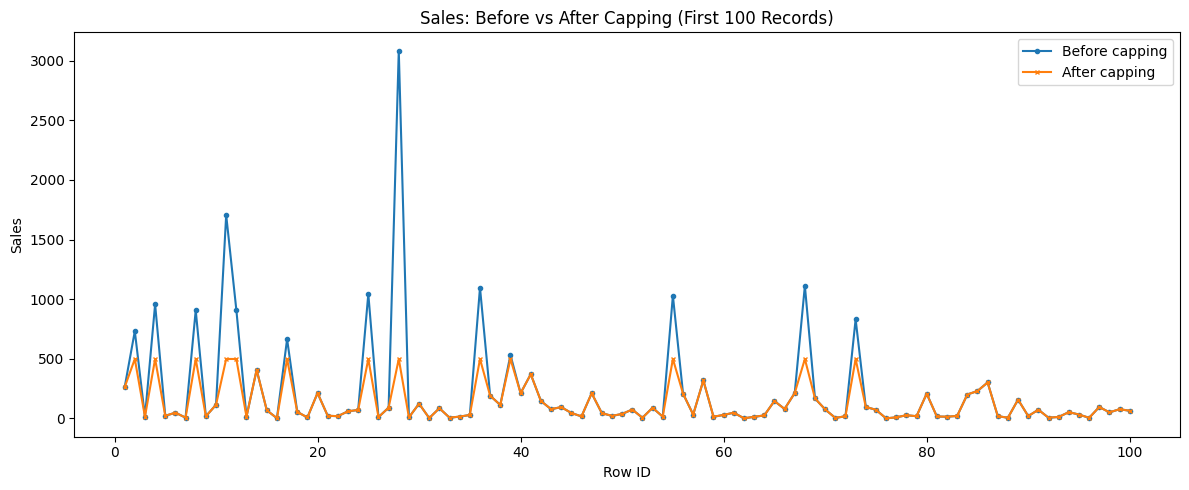

In [28]:
# Compare original and capped Sales values for the first 100 rows
comparison_rows = df[["Row ID", "Sales"]].head(100).copy()
comparison_rows["Capped Sales"] = df_capped["Sales"].head(100).values

plt.figure(figsize=(12, 5))
plt.plot(comparison_rows["Row ID"], comparison_rows["Sales"], label="Before capping", marker="o", markersize=3)
plt.plot(comparison_rows["Row ID"], comparison_rows["Capped Sales"], label="After capping", marker="x", markersize=3)
plt.title("Sales: Before vs After Capping (First 100 Records)")
plt.xlabel("Row ID")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

**explanation:** The line chart compares the first 100 original Sales values with their capped values. The two lines help show which observations are affected by the cap.

**Interpretation:** Where the lines overlap, capping has not changed the value. Where they differ, the original value was above the chosen upper limit.

**Limit:** This is a demonstration using only the first 100 rows and an IQR-based threshold. It does not establish that those transactions are errors.

**Recommendation:** Investigate extreme transactions with the business team before deciding whether to correct, retain or cap them.

## Lecture 8–10: Data visualisation and business questions

In [29]:
# Convert date columns into date format
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# Create delivery duration and month variables
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Order Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Order date range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Average delivery days:", round(df["Delivery Days"].mean(), 2))
df[["Order Date", "Ship Date", "Delivery Days", "Order Month"]].head()

Order date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Average delivery days: 3.96


,Order Date,Ship Date,Delivery Days,Order Month
0,2016-11-08,2016-11-11,3,2016-11
1,2016-11-08,2016-11-11,3,2016-11
2,2016-06-12,2016-06-16,4,2016-06
3,2015-10-11,2015-10-18,7,2015-10
4,2015-10-11,2015-10-18,7,2015-10


### Business problem 1: Are higher discounts associated with lower profit?

Discount
0.00     66.90
0.10     96.06
0.15     27.29
0.20     24.70
0.30    -45.68
0.32    -88.56
0.40   -111.93
0.45   -226.65
0.50   -310.70
0.60    -43.08
0.70    -95.87
0.80   -101.80
Name: Profit, dtype: float64


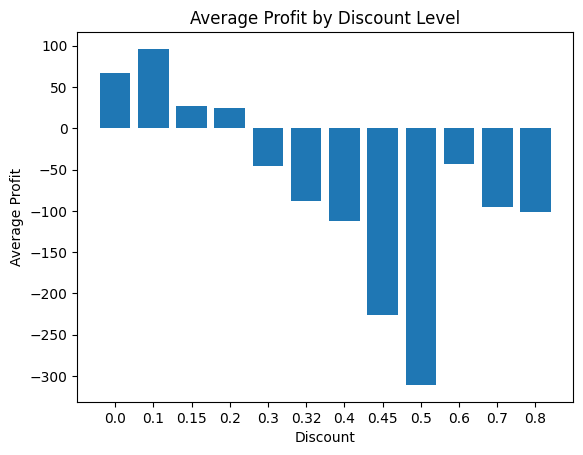

In [30]:
discount_profit = df.groupby("Discount")["Profit"].mean().sort_index()
print(discount_profit.round(2))

plt.bar(discount_profit.index.astype(str), discount_profit.values)
plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.show()

**explanation:** The data is grouped by discount level and the average Profit is calculated for each level. The bar chart compares the average transaction-line profit across discount levels.

**Limit:** Different products and order sizes may receive different discounts. This chart alone cannot prove that discounts caused a change in profit.

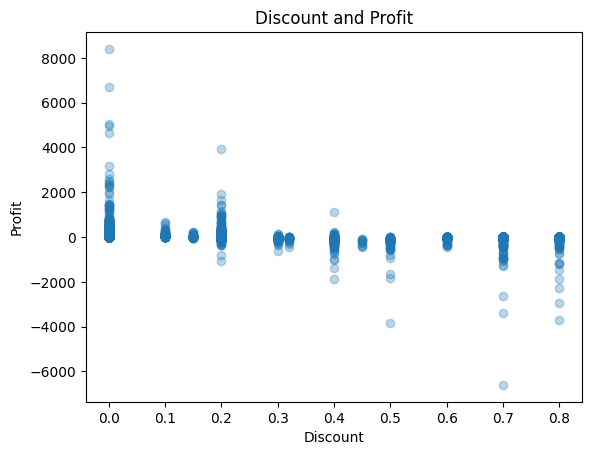

In [31]:
# Scatter plot: discount and profit
plt.scatter(df["Discount"], df["Profit"], alpha=0.3)
plt.title("Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

**explanation:** This code performs the calculation or creates the output shown above. Read the variable names and comments to identify the data being selected, transformed or displayed.


### Business problem 2: Which product categories and sub-categories perform best?

Category
Technology         836154.03
Furniture          741999.80
Office Supplies    719047.03
Name: Sales, dtype: float64


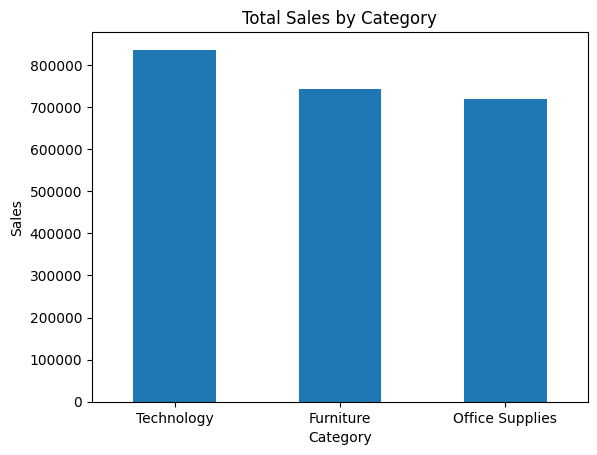

In [32]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales.round(2))

category_sales.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

Sub-Category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26590.17
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
Name: Profit, dtype: float64


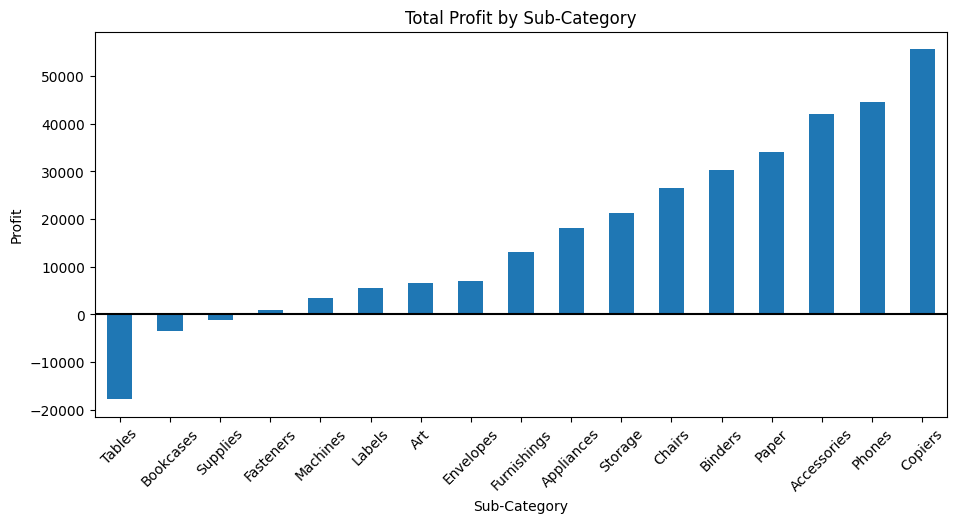

In [33]:
subcat_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
print(subcat_profit.round(2))

subcat_profit.plot(kind="bar", figsize=(11, 5))
plt.axhline(0, color="black")
plt.title("Total Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

**explanation:** The code adds Profit for each product sub-category and sorts the results from lowest to highest. The horizontal zero line separates total losses from total profits.

**Recommendation:** Management should investigate selling prices, discounts, purchase costs and product mix in loss-making sub-categories before deciding whether to change prices or promotions.

### Business problem 3: How do regions differ in sales and profit?

             Sales     Profit
Region                       
West     725457.82  108418.45
East     678781.24   91522.78
Central  501239.89   39706.36
South    391721.90   46749.43


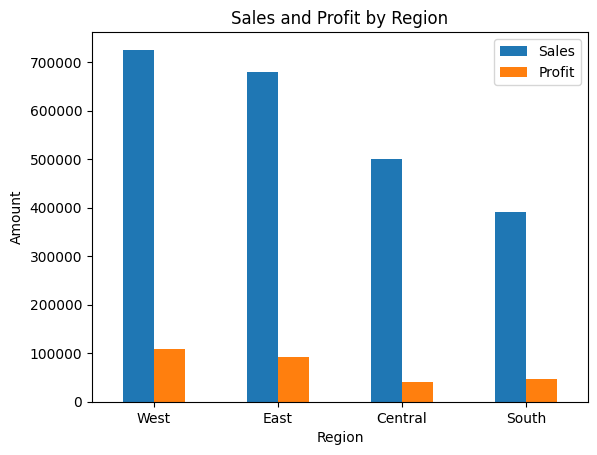

In [34]:
region_result = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
print(region_result.round(2))

region_result.plot(kind="bar")
plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

** explanation:** The records are grouped by Region and total Sales and Profit are calculated. The chart compares the two measures for each region.


**Recommendation:** Regional managers should compare profit as well as sales when setting targets. A region with high sales but weaker profit may need a review of discounting and product mix.



### Business problem 4: Which customer segments contribute most?

                  Sales     Profit
Segment                           
Consumer     1161401.34  134119.21
Corporate     706146.37   91979.13
Home Office   429653.15   60298.68


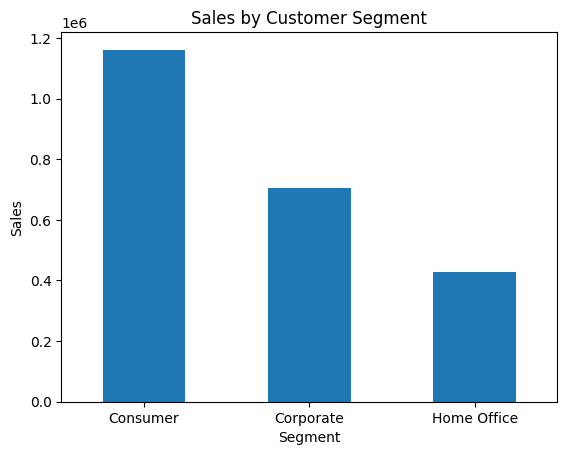

In [35]:
segment_result = df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
print(segment_result.round(2))

segment_result["Sales"].plot(kind="bar")
plt.title("Sales by Customer Segment")
plt.xlabel("Segment")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

**explanation:** This code groups records by customer Segment and calculates total Sales and Profit for Consumer, Corporate and Home Office customers.

**Interpretation:** The results show which customer group contributes most to the recorded sales and profit.

**Recommendation:** The marketing team can tailor offers and retention activity by segment, but should consider profit contribution rather than focusing only on sales.


### Business problem 5: How do shipping modes differ?

                Orders       Sales     Profit  Average_Delivery_Days
Ship Mode                                                           
First Class        787   351428.42   48969.84                   2.18
Same Day           264   128363.12   15891.76                   0.04
Second Class       964   459193.57   57446.64                   3.24
Standard Class    2994  1358215.74  164088.79                   5.01


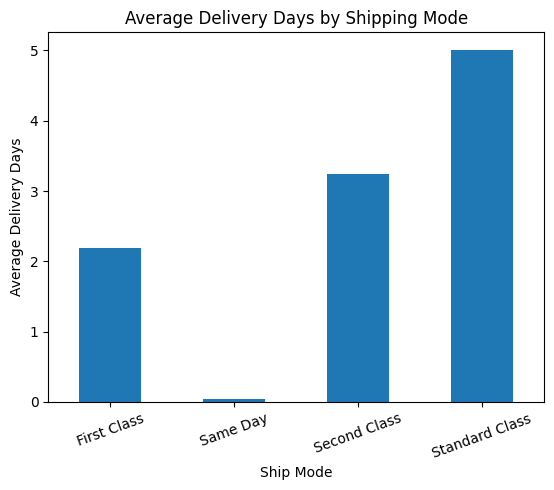

In [36]:
shipping_result = df.groupby("Ship Mode").agg(
    Orders=("Order ID", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Average_Delivery_Days=("Delivery Days", "mean")
)
print(shipping_result.round(2))

shipping_result["Average_Delivery_Days"].plot(kind="bar")
plt.title("Average Delivery Days by Shipping Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=20)
plt.show()

**explanation:** The data is grouped by Ship Mode. The code calculates the number of unique orders, total Sales, total Profit and average Delivery Days for each mode.

**Recommendation:** The operations manager should review whether the shipping service mix matches customer needs and operating costs.


### Other charts demonstrated in the lectures

### Group-wise summary tables for business comparison

### Annotated chart and subplots

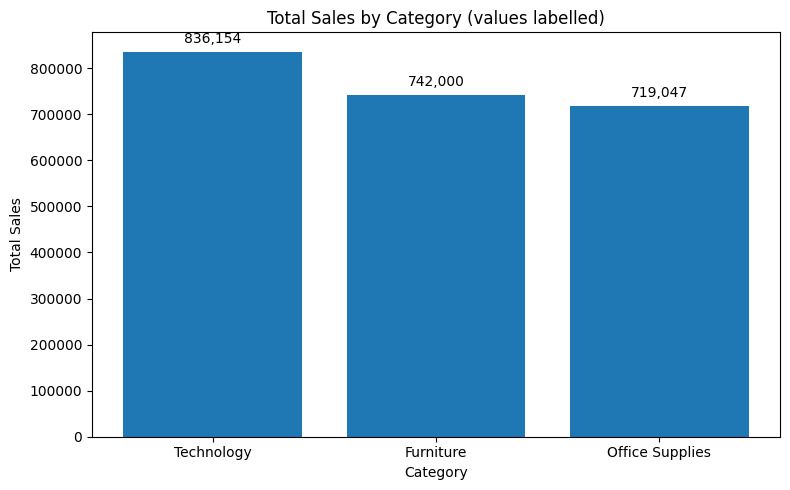

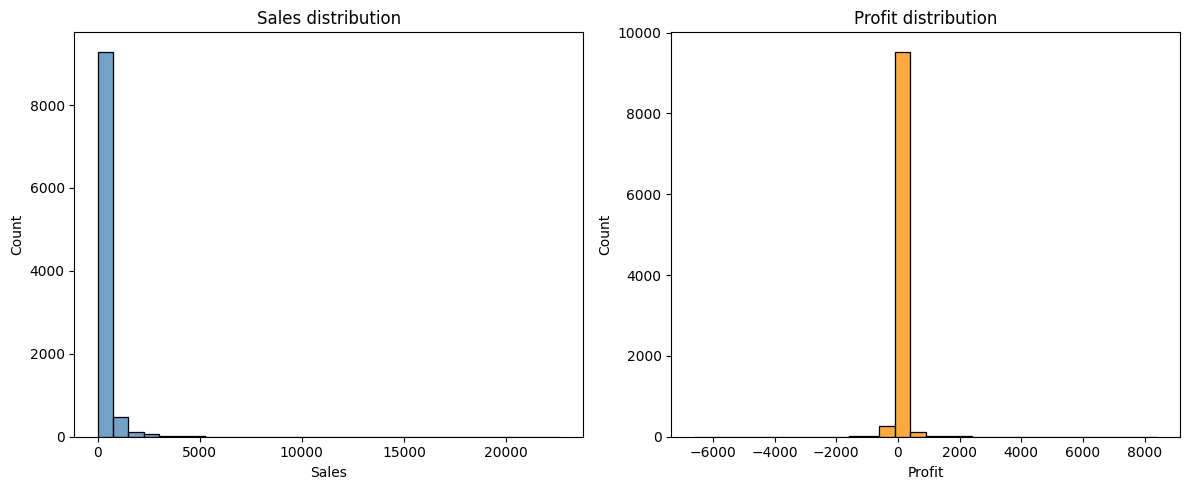

In [37]:
# Annotated bar chart: label the sales value above each category bar
category_sales_for_plot = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(category_sales_for_plot.index, category_sales_for_plot.values)
ax.set_title("Total Sales by Category (values labelled)")
ax.set_xlabel("Category")
ax.set_ylabel("Total Sales")
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,.0f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Subplots: compare the distributions of sales and profit
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["Sales"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Sales distribution")
axes[0].set_xlabel("Sales")
sns.histplot(df["Profit"], bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Profit distribution")
axes[1].set_xlabel("Profit")
plt.tight_layout()
plt.show()

**explanation:** The first chart writes the sales total above each category bar. The second figure uses two subplots so the sales and profit distributions can be viewed side by side.

**Interpretation:** Labels make category values easier to read. The subplots help compare the shape and spread of sales and profit.

**Limit:** Sales and profit have different ranges and meanings. The side-by-side charts are not a direct measure of performance or profitability.

**Recommendation:** Use annotations when exact values matter, and use subplots when two related distributions need to be compared.

In [38]:
# Summarise sales, profit and number of records by important business groups
for group_col in ["Category", "Sub-Category", "Region", "Segment", "Ship Mode"]:
    group_summary = df.groupby(group_col).agg(
        Records=("Row ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    ).sort_values("Profit", ascending=False)
    print("\nGROUP:", group_col)
    display(group_summary.round(2))


GROUP: Category


,Records,Sales,Profit,Average_Discount
Category,,,,
Technology,1847,836154.03,145454.95,0.13
Office Supplies,6026,719047.03,122490.80,0.16
Furniture,2121,741999.80,18451.27,0.17



GROUP: Sub-Category


,Records,Sales,Profit,Average_Discount
Sub-Category,,,,
Copiers,68,149528.03,55617.82,0.16
Phones,889,330007.05,44515.73,0.15
Accessories,775,167380.32,41936.64,0.08
Paper,1370,78479.21,34053.57,0.07
Binders,1523,203412.73,30221.76,0.37
Chairs,617,328449.10,26590.17,0.17
Storage,846,223843.61,21278.83,0.07
Appliances,466,107532.16,18138.01,0.17
Furnishings,957,91705.16,13059.14,0.14



GROUP: Region


,Records,Sales,Profit,Average_Discount
Region,,,,
West,3203,725457.82,108418.45,0.11
East,2848,678781.24,91522.78,0.15
South,1620,391721.90,46749.43,0.15
Central,2323,501239.89,39706.36,0.24



GROUP: Segment


,Records,Sales,Profit,Average_Discount
Segment,,,,
Consumer,5191,1161401.34,134119.21,0.16
Corporate,3020,706146.37,91979.13,0.16
Home Office,1783,429653.15,60298.68,0.15



GROUP: Ship Mode


,Records,Sales,Profit,Average_Discount
Ship Mode,,,,
Standard Class,5968,1358215.74,164088.79,0.16
Second Class,1945,459193.57,57446.64,0.14
First Class,1538,351428.42,48969.84,0.16
Same Day,543,128363.12,15891.76,0.15


**explanation:** This code groups transactions by product, region, customer segment and shipping method. It calculates record counts, total sales, total profit and average discount for each group.

**Interpretation:** A group with high sales but low or negative profit needs a different management response from a group that performs well on both measures.

**Limit:** The number of records is not the same as the number of unique orders or customers. These are historical group averages and totals.

**Recommendation:** Review groups using both sales and profit rather than ranking them by sales alone.

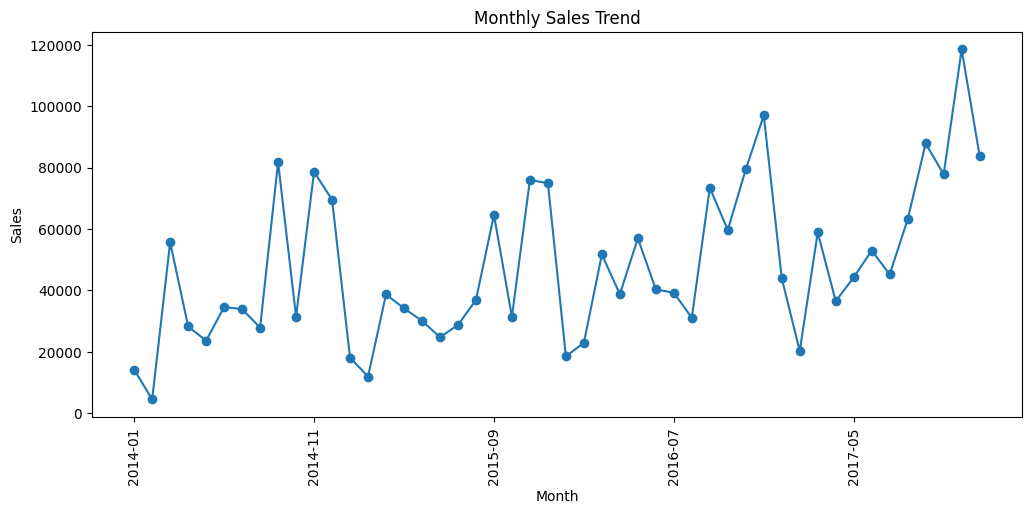

In [39]:
# Line chart: monthly sales trend
monthly_sales = df.groupby("Order Month")["Sales"].sum()

monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.show()

**explanation:** Sales are grouped by month and added together. A line chart shows how total monthly sales changed over the dataset period.

**Interpretation:** Peaks and dips show months with relatively higher or lower sales. Look for recurring seasonal patterns, but compare several years before concluding that a pattern repeats.


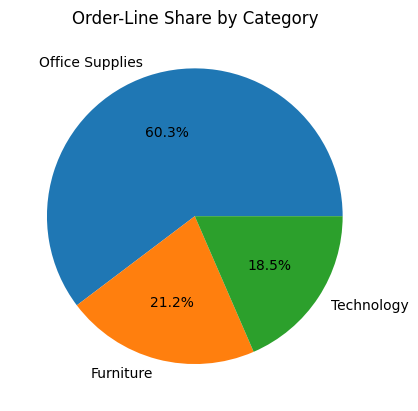

In [40]:
# Pie chart: order-line share by category
category_count = df["Category"].value_counts()

plt.pie(
    category_count.values,
    labels=category_count.index,
    autopct="%1.1f%%"
)
plt.title("Order-Line Share by Category")
plt.show()

** explanation:** This pie chart shows the percentage of order-line records in each product category.



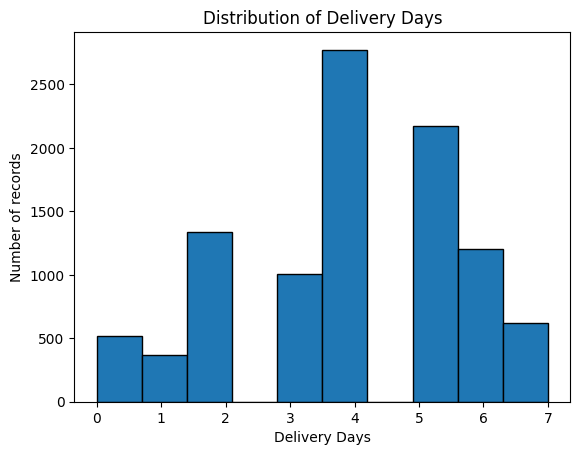

In [41]:
# Histogram: delivery days
plt.hist(df["Delivery Days"], bins=10, edgecolor="black")
plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Days")
plt.ylabel("Number of records")
plt.show()

**explanation:** The histogram groups Delivery Days into intervals and shows how many records fall into each interval.

**Interpretation:** The tallest bars show the most common delivery durations. The shape helps identify whether delivery times are concentrated or spread out.


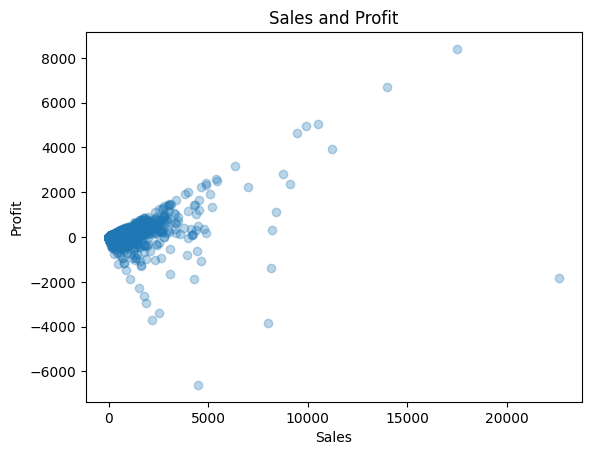

In [42]:
# Scatter plot: sales and profit
plt.scatter(df["Sales"], df["Profit"], alpha=0.3)
plt.title("Sales and Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

### Contour plot: estimated profit for different sales and discount combinations

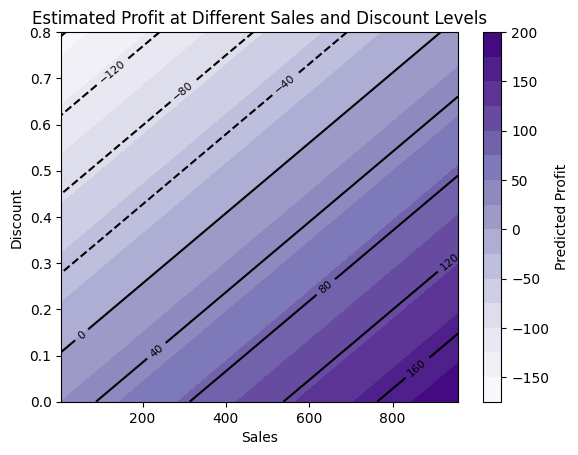

In [43]:
# Linear regression model for a simple what-if illustration
from sklearn.linear_model import LinearRegression

contour_model = LinearRegression().fit(
    df[["Sales", "Discount"]],
    df["Profit"]
)

# Create possible Sales and Discount combinations
sales_values = np.linspace(df["Sales"].quantile(0.05), df["Sales"].quantile(0.95), 40)
discount_values = np.linspace(df["Discount"].min(), df["Discount"].max(), 30)

S, D = np.meshgrid(sales_values, discount_values)

cases = pd.DataFrame({
    "Sales": S.ravel(),
    "Discount": D.ravel()
})

P = contour_model.predict(cases).reshape(S.shape)

plt.contourf(S, D, P, levels=15, cmap="Purples")
plt.colorbar(label="Predicted Profit")
lines = plt.contour(S, D, P, levels=8, colors="black")
plt.clabel(lines, inline=True, fontsize=8)

plt.title("Estimated Profit at Different Sales and Discount Levels")
plt.xlabel("Sales")
plt.ylabel("Discount")
plt.show()

**explanation:** A simple regression model is fitted using Sales and Discount to estimate Profit. The contour plot then displays the model's predicted profit across combinations of sales and discount values.

**Interpretation:** The colour regions and contour lines show how the fitted model's predicted profit changes as Sales and Discount change.


### Animated chart: cumulative sales by region over time

In [44]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Monthly sales by region, shown as a running total
monthly_region = df.pivot_table(
    index="Order Month",
    columns="Region",
    values="Sales",
    aggfunc="sum"
).fillna(0).cumsum()

fig, ax = plt.subplots(figsize=(8, 5))

def draw(i):
    ax.clear()
    values = monthly_region.iloc[i].sort_values()
    ax.barh(values.index, values.values, color="#6A1B9A")
    ax.set_xlim(0, monthly_region.values.max() * 1.1)
    ax.set_title("Cumulative Sales up to " + str(monthly_region.index[i]))
    ax.set_xlabel("Cumulative Sales")

animation = FuncAnimation(
    fig,
    draw,
    frames=len(monthly_region),
    interval=500
)

plt.close()
HTML(animation.to_jshtml())

**explanation:** This animation shows cumulative sales by region as the months progress. Each frame adds another month to the running sales total.

**Interpretation:** It helps demonstrate how each region's accumulated sales develop over time.


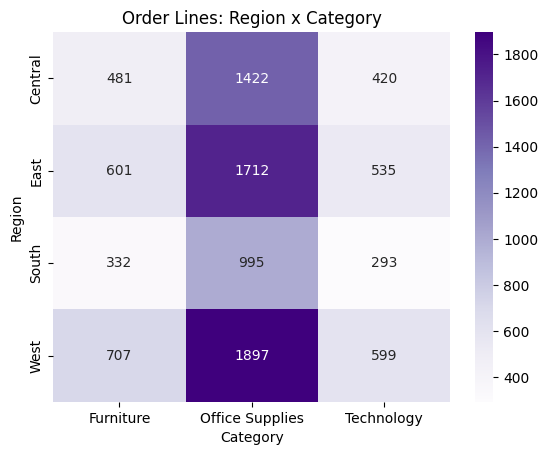

In [46]:
# Heatmap: region and category order-line counts
region_category = pd.crosstab(df["Region"], df["Category"])

sns.heatmap(region_category, annot=True, fmt="d", cmap="Purples")
plt.title("Order Lines: Region x Category")
plt.show()

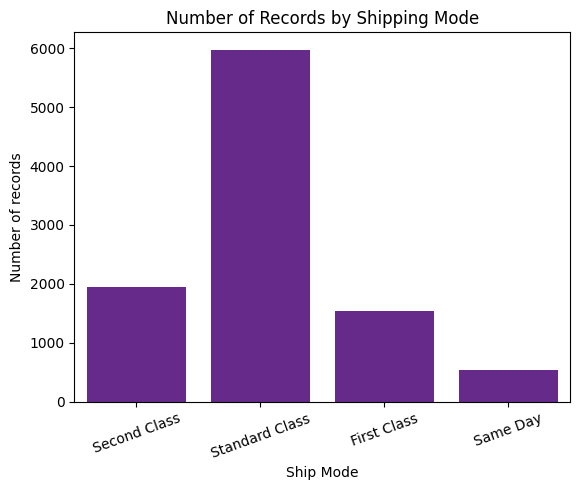

In [45]:
# Seaborn countplot: which shipping mode has most records?
sns.countplot(data=df, x="Ship Mode", color="#6A1B9A")
plt.title("Number of Records by Shipping Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.show()

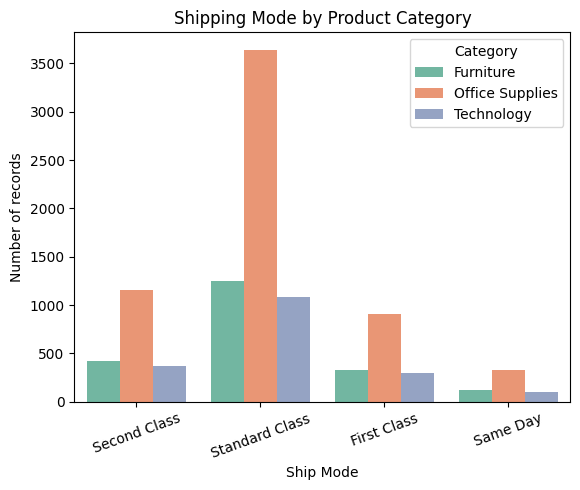

In [47]:
# Seaborn countplot with category comparison
sns.countplot(data=df, x="Ship Mode", hue="Category", palette="Set2")
plt.title("Shipping Mode by Product Category")
plt.xlabel("Ship Mode")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.show()

**explanation:** This countplot compares the number of records for each shipping mode and separates the bars by product category.

**Interpretation:** It helps show whether some shipping modes are more common for particular product categories.



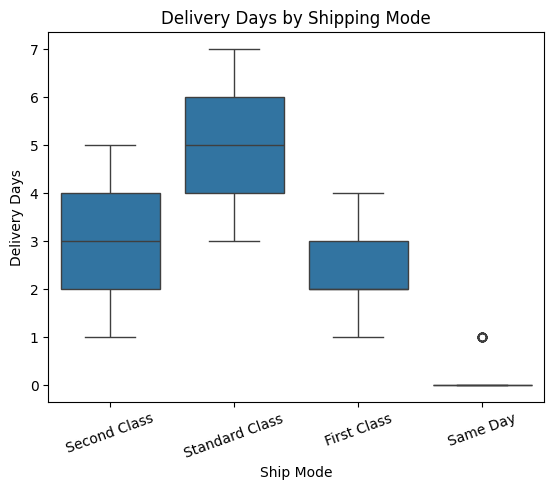

In [48]:
# Seaborn boxplot: delivery duration by shipping mode
sns.boxplot(data=df, x="Ship Mode", y="Delivery Days")
plt.title("Delivery Days by Shipping Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Delivery Days")
plt.xticks(rotation=20)
plt.show()

**explanation:** This boxplot compares the distribution of Delivery Days across shipping modes. It shows the median, spread and potential unusual delivery durations for each mode.


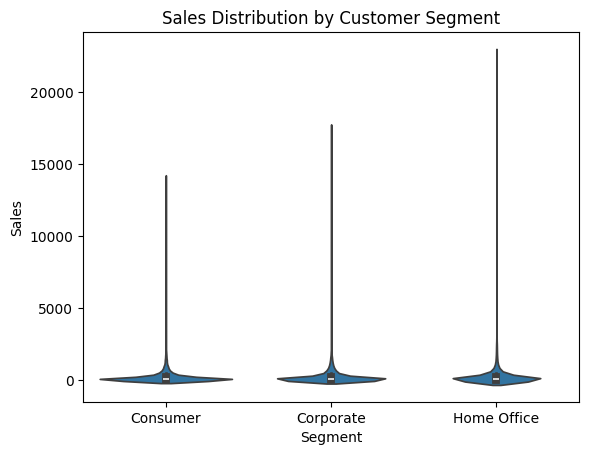

In [49]:
# Violin plot: sales distribution by customer segment
sns.violinplot(data=df, x="Segment", y="Sales")
plt.title("Sales Distribution by Customer Segment")
plt.xlabel("Segment")
plt.ylabel("Sales")
plt.show()

**explanation:** The violin plot compares the distribution of Sales across customer segments. The width of each violin indicates where more observations are concentrated.

**Interpretation:** It helps compare the typical range and shape of transaction sales for each segment.


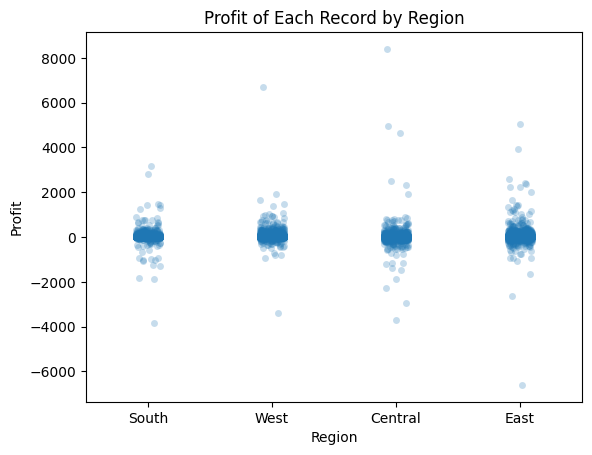

In [50]:
# Stripplot: transaction profit by region
sns.stripplot(data=df, x="Region", y="Profit", jitter=True, alpha=0.25)
plt.title("Profit of Each Record by Region")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.show()

**explanation:** Each point in the stripplot represents a record's Profit, grouped by Region. Jitter spreads overlapping points slightly so that more records can be seen.

**Interpretation:** The plot shows the spread of profit and loss transactions within each region.



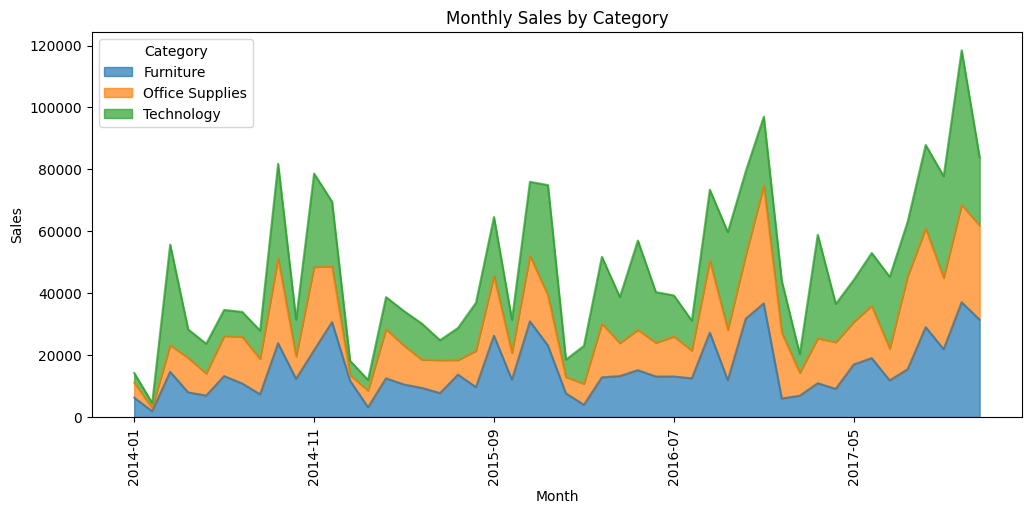

In [51]:
# Area chart: monthly sales by category
month_category = df.pivot_table(
    index="Order Month",
    columns="Category",
    values="Sales",
    aggfunc="sum"
).fillna(0)

month_category.plot(kind="area", alpha=0.7, figsize=(12, 5))
plt.title("Monthly Sales by Category")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.show()

## Lecture 11–14: Statistics, correlation, regression and PCA

### Correlation between key numerical variables

In [52]:
key_cols = ["Sales", "Profit", "Quantity", "Discount", "Delivery Days"]

corr = df[key_cols].corr().round(2)
corr

,Sales,Profit,Quantity,Discount,Delivery Days
Sales,1.00,0.48,0.20,-0.03,-0.01
Profit,0.48,1.00,0.07,-0.22,-0.00
Quantity,0.20,0.07,1.00,0.01,0.02
Discount,-0.03,-0.22,0.01,1.00,0.00
Delivery Days,-0.01,-0.00,0.02,0.00,1.00




**Interpretation:** A positive value means two variables tend to move in the same direction. A negative value means they tend to move in opposite directions. Values near zero indicate a weak linear relationship.



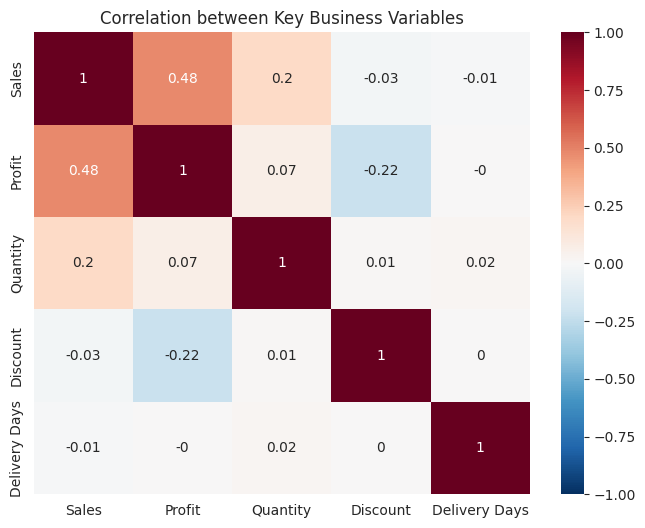

In [53]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between Key Business Variables")
plt.show()

**explanation:** The heatmap presents the correlation matrix as colours and numbers. This makes strong positive and negative relationships easier to identify.


### Simple linear regression: discount and profit

In [54]:
import statsmodels.formula.api as smf

m_discount = smf.ols(
    "Profit ~ Discount",
    data=df
).fit()

print(m_discount.summary().tables[1])
print("R-squared:", round(m_discount.rsquared, 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     67.5594      2.867     23.565      0.000      61.940      73.179
Discount    -249.0514     11.075    -22.488      0.000    -270.760    -227.343
R-squared: 0.048


** explanation:** This is a simple linear regression with Profit as the outcome and Discount as the explanatory variable. The coefficient estimates the average change in Profit associated with a one-unit increase in Discount.

**Interpretation:** Check the Discount coefficient, its p-value and the R-squared value. A p-value below 0.05 is commonly treated as statistically significant in this class exercise. R-squared shows the proportion of variation in Profit explained by this one-variable model.


### Simple linear regression: sales and profit

In [55]:
m_sales = smf.ols(
    "Profit ~ Sales",
    data=df
).fit()

print(m_sales.summary().tables[1])
print("R-squared:", round(m_sales.rsquared, 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.7329      2.192     -5.808      0.000     -17.031      -8.435
Sales          0.1801      0.003     54.555      0.000       0.174       0.187
R-squared: 0.23


** explanation:** This simple regression examines the relationship between Sales and Profit. Profit is the outcome variable and Sales is the explanatory variable.

**Interpretation:** The Sales coefficient indicates the estimated change in Profit associated with a one-unit increase in Sales. Check its p-value and R-squared to understand statistical evidence and explanatory power.



### Multiple regression: control for sales and quantity

In [56]:
m_discount_alone = smf.ols(
    "Profit ~ Discount",
    data=df
).fit()

m_discount_control = smf.ols(
    "Profit ~ Discount + Sales + Quantity",
    data=df
).fit()

print("Discount alone:")
print(m_discount_alone.summary().tables[1])
print("R-squared:", round(m_discount_alone.rsquared, 3))

print("\nDiscount with controls:")
print(m_discount_control.summary().tables[1])
print("R-squared:", round(m_discount_control.rsquared, 3))

print(
    "Discount coefficient alone:",
    round(m_discount_alone.params["Discount"], 2),
    "| p-value:",
    round(m_discount_alone.pvalues["Discount"], 3)
)

print(
    "Discount coefficient with controls:",
    round(m_discount_control.params["Discount"], 2),
    "| p-value:",
    round(m_discount_control.pvalues["Discount"], 3)
)

Discount alone:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     67.5594      2.867     23.565      0.000      61.940      73.179
Discount    -249.0514     11.075    -22.488      0.000    -270.760    -227.343
R-squared: 0.048

Discount with controls:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.9721      4.218      8.291      0.000      26.704      43.240
Discount    -233.4570      9.686    -24.101      0.000    -252.444    -214.470
Sales          0.1800      0.003     54.961      0.000       0.174       0.186
Quantity      -2.9622      0.917     -3.230      0.001      -4.760      -1.165
R-squared: 0.273
Discount coefficient alone: -249.05 | p-value: 0.0
Discount coefficient with controls: -233.46 | p-value: 0.0


** explanation:** The code compares a simple regression using Discount alone with a multiple regression that also includes Sales and Quantity. This helps us see whether the estimated discount relationship changes after accounting for two other numerical variables.

**Interpretation:** Compare the Discount coefficient and p-value across both models. A change after adding controls means the simple relationship partly reflected differences associated with Sales or Quantity.



### Moderation effect: does the sales-profit relationship change at different discount levels?

In [57]:
# Centre numerical variables by subtracting their averages
df["Sales_c"] = df["Sales"] - df["Sales"].mean()
df["Discount_c"] = df["Discount"] - df["Discount"].mean()

m_moderation = smf.ols(
    "Profit ~ Sales_c * Discount_c",
    data=df
).fit()

print(m_moderation.summary().tables[1])
print("R-squared:", round(m_moderation.rsquared, 3))

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             24.1664      1.251     19.320      0.000      21.715      26.618
Sales_c                0.1851      0.002     92.192      0.000       0.181       0.189
Discount_c          -327.7323      6.106    -53.678      0.000    -339.700    -315.764
Sales_c:Discount_c    -1.2381      0.010   -124.753      0.000      -1.258      -1.219
R-squared: 0.715


**explanation:** Sales and Discount are centred by subtracting their averages. The model then includes Sales, Discount and their interaction. The interaction tests whether the relationship between Sales and Profit differs at different discount levels.


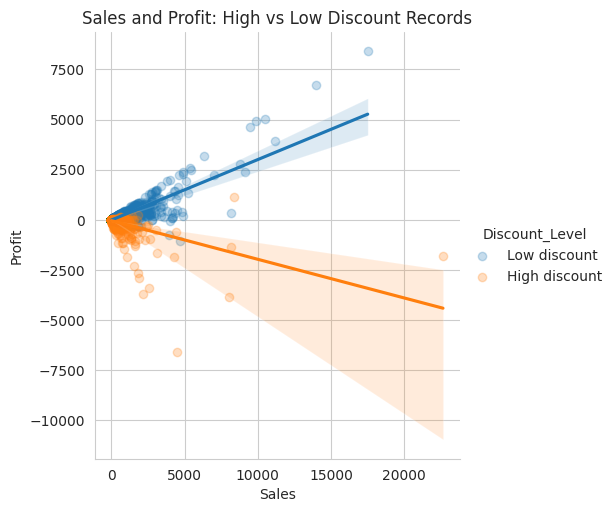

In [58]:
# Create high and low discount groups using the median
df["Discount_Level"] = np.where(
    df["Discount"] > df["Discount"].median(),
    "High discount",
    "Low discount"
)

g = sns.lmplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Discount_Level",
    height=5,
    scatter_kws={"alpha": 0.25}
)

g.set(title="Sales and Profit: High vs Low Discount Records")
plt.show()

** explanation:** The records are divided into high- and low-discount groups using the median discount. The plot displays the Sales-Profit relationship separately for the two groups, with fitted trend lines.



### PCA / logical index

For PCA, used the  numerical transaction variables that represent sales value, profit, quantity, discount and delivery duration. PCA combines correlated numerical measures into components. The resulting index is a statistical summary of transaction characteristics

In [59]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_cols = ["Sales", "Profit", "Quantity", "Discount", "Delivery Days"]

# Step A: Standardise variables so they are on a comparable scale
scaled = StandardScaler().fit_transform(df[pca_cols])

# Step B: Run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: Variance explained by each component
names = [f"PC{i+1}" for i in range(len(pca_cols))]

print(
    pd.Series(
        pca.explained_variance_ratio_,
        index=names
    ).round(3)
)

PC1    0.318
PC2    0.212
PC3    0.200
PC4    0.176
PC5    0.094
dtype: float64


** explanation:** PCA is applied to five numerical variables after standardisation. Standardisation puts the variables on a comparable scale. PCA then creates new components that summarise patterns across the original variables.

**Interpretation:** The explained-variance ratios show how much of the overall variation is captured by each component. A larger share for PC1 means the first component summarises more of the variation.


In [60]:
# Step D: Loadings show how much each variable contributes to PC1
sign = 1 if pca.components_[0].sum() > 0 else -1

print(
    pd.Series(
        pca.components_[0] * sign,
        index=pca_cols
    ).round(3)
)

Sales            0.643
Profit           0.655
Quantity         0.289
Discount        -0.270
Delivery Days   -0.004
dtype: float64


**explanation:** This code displays the loadings for the first principal component. Loadings show how strongly each original variable contributes to that component. The sign adjustment makes the overall direction easier to read.

**Interpretation:** Variables with larger absolute loadings contribute more strongly to PC1. Consider both the size and direction of each loading.



In [61]:
# Create a 0–100 transaction profile index from PC1
raw_index = scores[:, 0] * sign

df["Transaction_Profile_Index"] = (
    (raw_index - raw_index.min()) /
    (raw_index.max() - raw_index.min()) * 100
)

df[["Order ID", "Product Name", "Transaction_Profile_Index"]].sort_values(
    "Transaction_Profile_Index",
    ascending=False
).head(10).round(1)

,Order ID,Product Name,Transaction_Profile_Index
6826,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,100.0
8153,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,85.0
9039,CA-2016-117121,GBC Ibimaster 500 Manual ProClick Binding System,70.7
4190,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,70.0
4098,CA-2014-116904,Ibico EPK-21 Electric Binding System,66.5
2623,CA-2017-127180,Canon imageCLASS 2200 Advanced Copier,65.5
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,57.8
8488,CA-2016-158841,HP Designjet T520 Inkjet Large Format Printer ...,56.2
4277,US-2016-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",55.1
509,CA-2015-145352,Fellowes PB500 Electric Punch Plastic Comb Bin...,53.6


**explanation:** The first principal component score is rescaled to a 0–100 range and stored as a transaction profile index. The code then displays the ten records with the highest index values.

**Interpretation:** A higher score means a record is positioned higher on this particular mathematical combination of Sales, Profit, Quantity, Discount and Delivery Days.


## Final verification: summary figures from Python

In [62]:
summary = pd.DataFrame({
    "Measure": [
        "Number of records",
        "Unique orders",
        "Total sales",
        "Total profit",
        "Profit margin",
        "Average discount",
        "Average delivery days"
    ],
    "Result": [
        len(df),
        df["Order ID"].nunique(),
        df["Sales"].sum(),
        df["Profit"].sum(),
        df["Profit"].sum() / df["Sales"].sum(),
        df["Discount"].mean(),
        df["Delivery Days"].mean()
    ]
})

summary.round(3)

,Measure,Result
0,Number of records,9994.000
1,Unique orders,5009.000
2,Total sales,2297200.860
3,Total profit,286397.022
4,Profit margin,0.125
5,Average discount,0.156
6,Average delivery days,3.958


** explanation:** This final table collects the main measures used in the report: record count, unique orders, total sales, total profit, profit margin, average discount and average delivery duration.

**Interpretation:** Using this table as the final source for headline figures in report.



## Business solutions – evidence, finding and action



| Problem | Evidence to quote from Python | Business solution | Owner | Timeline | Expected benefit |
|---|---|---|---|---|---|
| Discounts and profit | Discount-profit groupby, correlation and regression | Set discount approval limits and review high-discount transactions | Pricing / Sales Manager | 30 days | Reduce avoidable losses |
| Product performance | Category and sub-category sales/profit tables | Review pricing, sourcing and promotion of loss-making sub-categories | Category Manager | 30–60 days | Improve product-level profit |
| Regional performance | Region sales and profit table | Prepare region-specific sales and margin plans | Regional Sales Managers | 60 days | Improve regional contribution |
| Customer segments | Segment sales and profit table | Develop segment-wise offers based on contribution, not sales alone | Marketing Manager | 45 days | Improve profitable customer retention |
| Shipping performance | Shipping-mode delivery, sales and profit table | Review shipping service mix and delivery performance | Operations Manager | 60 days | Improve delivery efficiency and cost control |

### Overall recommendation

The retailer should focus on profitable growth rather than sales growth alone. Management should review discounts, correct loss-making product economics, build region- and segment-specific plans, and monitor shipping performance. The business should track sales and profit together when evaluating each action.

## Integrated recommendations and reflection

The five business problems should be considered together. The business should protect profit while growing sales, review discount levels alongside product mix, investigate loss-making sub-categories, compare regional performance using both sales and profit, and monitor delivery performance by shipping mode. These recommendations are based on patterns in the historical dataset and should be tested through small, monitored changes before wider implementation.

**Limitations and reflection**
- The dataset is historical and covers a limited period; current market conditions may be different.
- Each row represents an order line, not necessarily a complete order. Order counts must use unique Order IDs.
- The data does not include marketing spend, inventory costs, competitor prices, customer satisfaction or detailed operating costs.
- Correlation and regression show relationships in the available data; they do not prove cause and effect.
- PCA creates a combined statistical profile from the selected numerical variables. It is not a customer satisfaction score or a direct measure of business success.
- The contour plot is a model-based illustration and should not be treated as a guaranteed profit forecast.

**Reflection:** The analysis is useful for identifying where managers should investigate further. Before making a major pricing, product or delivery decision, the company should combine these findings with cost, customer and operational information that is not available in this dataset.